
# AI Sales Analytics Copilot
## 01 — Exploratory Data Analysis (EDA)

### Project objective
Analyze retail sales data to understand sales performance,
profitability, customer segments, regional performance, and
product trends.

### Analysis workflow
1. Load and inspect the raw dataset.
2. Validate data types and data quality.
3. Investigate missing values and duplicate records.
4. Analyze sales, profit, quantity, and discount metrics.
5. Identify business questions for further investigation.

### Dataset
Source file: `data/raw/Superstore.csv`

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook


In [22]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



print("All libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


All libraries imported successfully.
Pandas version: 3.1.0
NumPy version: 2.5.4


In [25]:

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Superstore.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# Create output directories if they do not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", RAW_DATA_PATH)
print("Dataset exists:", RAW_DATA_PATH.exists())


Project root: d:\AI\AI POWERED SALES ANALYTICS COPILOT
Dataset path: d:\AI\AI POWERED SALES ANALYTICS COPILOT\data\raw\Superstore.csv
Dataset exists: True


In [27]:
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {RAW_DATA_PATH}"
    )

df = pd.read_csv(RAW_DATA_PATH, encoding="latin1")

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 9994
Number of columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [28]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [29]:
df.describe()



,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [30]:
df.info

<bound method DataFrame.info of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
1          2  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
2          3  CA-2016-138688   6/12/2016   6/16/2016    Second Class   
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9991    9992  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9992    9993  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9993    9994  CA-2017-119914    5/4/2017    5/9/2017    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520      

In [31]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [32]:
df.shape

(9994, 21)

In [33]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [34]:
df.info

<bound method DataFrame.info of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
1          2  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
2          3  CA-2016-138688   6/12/2016   6/16/2016    Second Class   
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9991    9992  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9992    9993  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9993    9994  CA-2017-119914    5/4/2017    5/9/2017    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520      

In [35]:
df.isnull

<bound method DataFrame.isnull of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
1          2  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
2          3  CA-2016-138688   6/12/2016   6/16/2016    Second Class   
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9991    9992  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9992    9993  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9993    9994  CA-2017-119914    5/4/2017    5/9/2017    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520    

In [36]:
df.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [39]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9989    False
9990    False
9991    False
9992    False
9993    False
Length: 9994, dtype: bool

In [41]:


# STANDARDIZATIONS  IN COLUMNS
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


In [42]:
date_columns = ["order_date", "ship_date"]

for column in date_columns:
    if column in df.columns:
        df[column] = pd.to_datetime(
            df[column],
            errors="coerce"
        )

print(df.dtypes)


row_id                    int64
order_id                    str
order_date       datetime64[us]
ship_date        datetime64[us]
ship_mode                   str
customer_id                 str
customer_name               str
segment                     str
country                     str
city                        str
state                       str
postal_code               int64
region                      str
product_id                  str
category                    str
sub_category                str
product_name                str
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object


In [43]:

if "sales" in df.columns:
    print("Negative sales:", (df["sales"] < 0).sum())
    print("Zero sales:", (df["sales"] == 0).sum())

if "quantity" in df.columns:
    print("Negative quantities:", (df["quantity"] < 0).sum())
    print("Zero quantities:", (df["quantity"] == 0).sum())

if "profit" in df.columns:
    print("Negative profit:", (df["profit"] < 0).sum())


Negative sales: 0
Zero sales: 0
Negative quantities: 0
Zero quantities: 0
Negative profit: 1871


In [44]:

required_columns = {"sales", "profit", "quantity"}

if required_columns.issubset(df.columns):
    total_sales = df["sales"].sum()
    total_profit = df["profit"].sum()
    total_quantity = df["quantity"].sum()

    profit_margin = (
        total_profit / total_sales * 100
        if total_sales != 0
        else np.nan
    )

    order_count = (
        df["order_id"].nunique()
        if "order_id" in df.columns
        else None
    )

    customer_count = (
        df["customer_id"].nunique()
        if "customer_id" in df.columns
        else None
    )

    kpis = {
        "Total Sales": total_sales,
        "Total Profit": total_profit,
        "Total Quantity": total_quantity,
        "Profit Margin (%)": profit_margin,
        "Unique Orders": order_count,
        "Unique Customers": customer_count,
    }

    for name, value in kpis.items():
        if isinstance(value, (int, float, np.number)):
            print(f"{name}: {value:,.2f}")
        else:
            print(f"{name}: {value}")
else:
    print("Some required columns are missing. Check the dataset.")


Total Sales: 2,297,200.86
Total Profit: 286,397.02
Total Quantity: 37,873.00
Profit Margin (%): 12.47
Unique Orders: 5,009.00
Unique Customers: 793.00


In [45]:
 
if {"category", "sales", "profit"}.issubset(df.columns):
    category_summary = (
        df.groupby("category", dropna=False)
        .agg(
            total_sales=("sales", "sum"),
            total_profit=("profit", "sum"),
            total_quantity=("quantity", "sum"),
            transaction_lines=("sales", "size")
        )
        .sort_values("total_sales", ascending=False)
    )

    display(category_summary.round(2))


,total_sales,total_profit,total_quantity,transaction_lines
category,,,,
Technology,836154.03,145454.95,6939,1847
Furniture,741999.80,18451.27,8028,2121
Office Supplies,719047.03,122490.80,22906,6026


In [46]:

if {"region", "sales", "profit"}.issubset(df.columns):
    region_summary = (
        df.groupby("region", dropna=False)
        .agg(
            total_sales=("sales", "sum"),
            total_profit=("profit", "sum"),
            total_quantity=("quantity", "sum")
        )
        .sort_values("total_sales", ascending=False)
    )

    display(region_summary.round(2))


,total_sales,total_profit,total_quantity
region,,,
West,725457.82,108418.45,12266
East,678781.24,91522.78,10618
Central,501239.89,39706.36,8780
South,391721.90,46749.43,6209



# 02 — Business Data Visualization

This section explores sales performance, profitability, regional
differences, monthly trends, product performance, and the
relationship between discounts and profit.

All charts are saved as reusable image files for reporting
and business presentations.


In [48]:

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Visualization environment ready.")
print("Charts will be saved to:", FIGURES_DIR)


Visualization environment ready.
Charts will be saved to: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures


In [49]:

def finish_chart(fig, filename):
    fig.tight_layout()

    output_path = FIGURES_DIR / filename
    fig.savefig(
        output_path,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


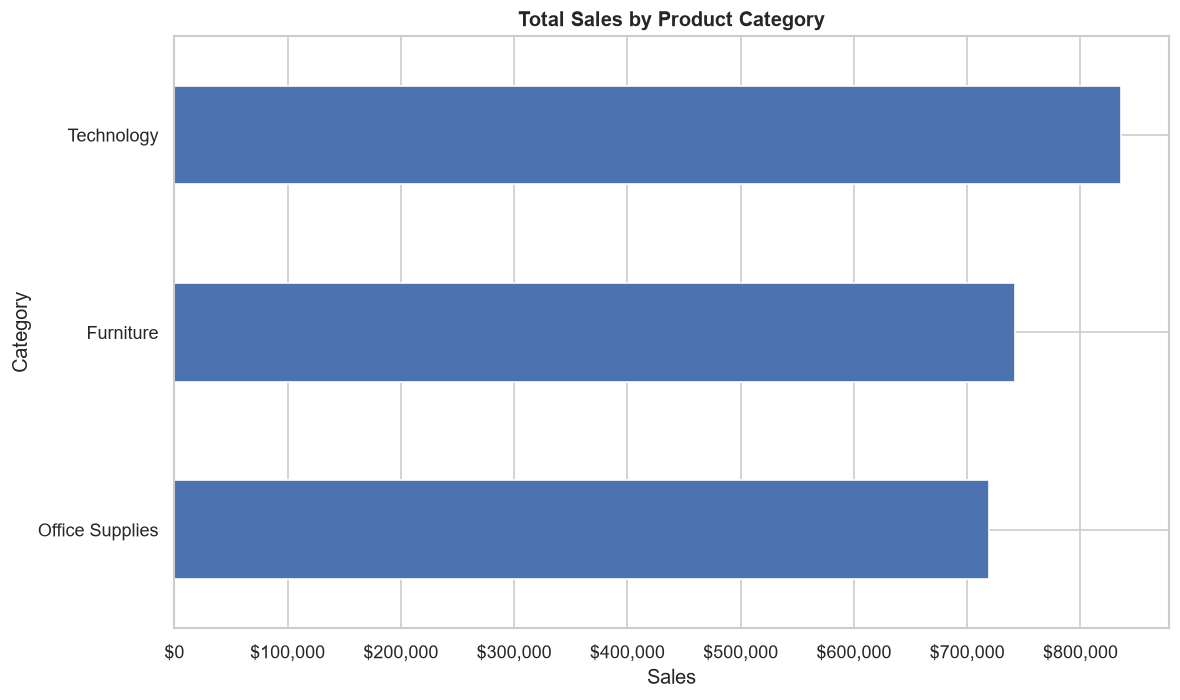

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\01_sales_by_category.png


In [50]:

if {"category", "sales"}.issubset(df.columns):
    category_sales = (
        df.groupby("category")["sales"]
        .sum()
        .sort_values(ascending=True)
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    category_sales.plot(
        kind="barh",
        ax=ax
    )

    ax.set_title("Total Sales by Product Category")
    ax.set_xlabel("Sales")
    ax.set_ylabel("Category")
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
    )

    finish_chart(fig, "01_sales_by_category.png")
else:
    print("Required columns are missing.")


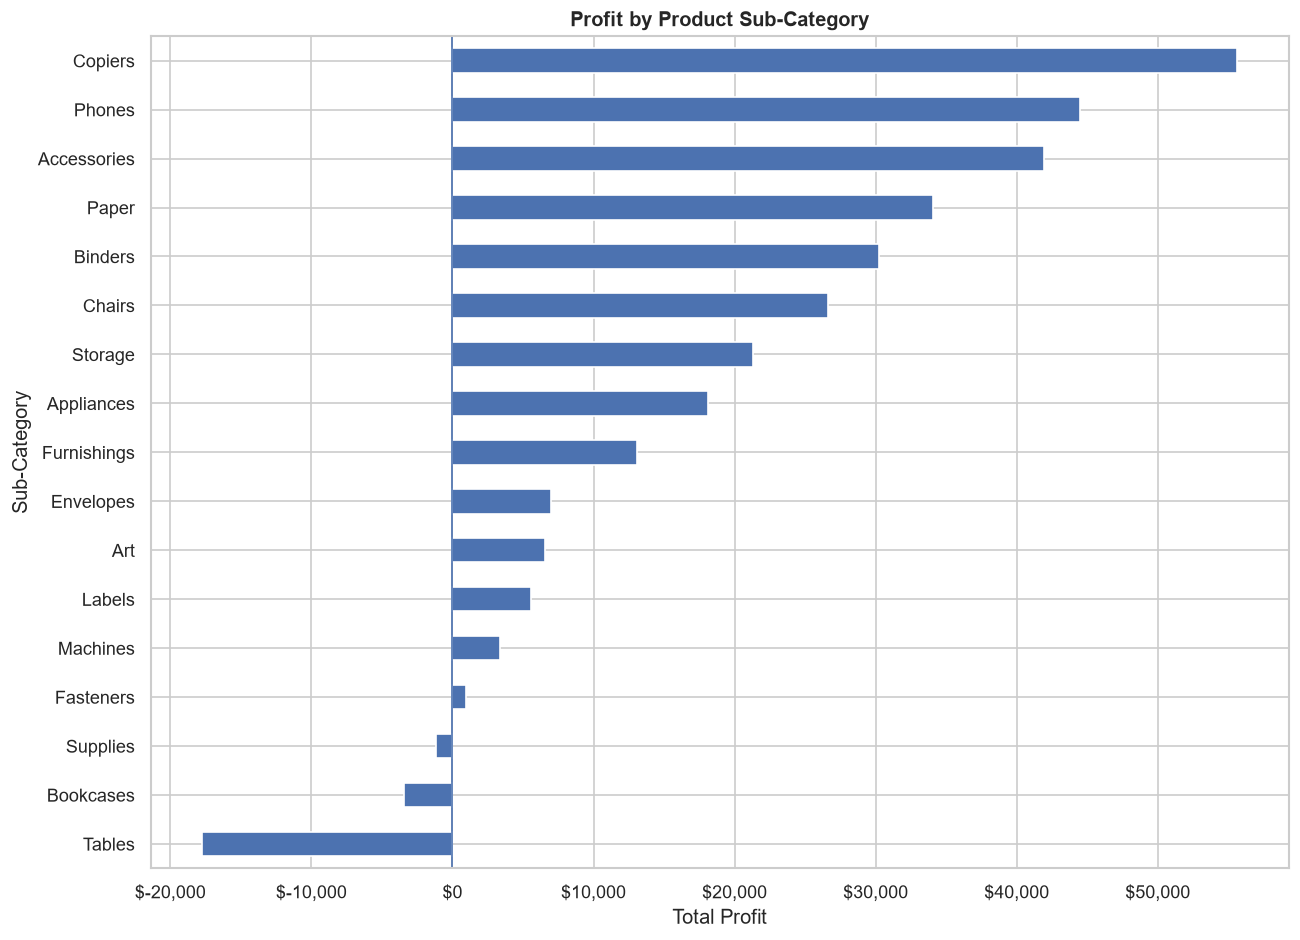

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\02_profit_by_subcategory.png


In [51]:

if {"sub_category", "profit"}.issubset(df.columns):
    subcategory_profit = (
        df.groupby("sub_category")["profit"]
        .sum()
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(11, 8))

    subcategory_profit.plot(
        kind="barh",
        ax=ax
    )

    ax.axvline(0, linewidth=1)
    ax.set_title("Profit by Product Sub-Category")
    ax.set_xlabel("Total Profit")
    ax.set_ylabel("Sub-Category")
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
    )

    finish_chart(fig, "02_profit_by_subcategory.png")
else:
    print("Required columns are missing.")


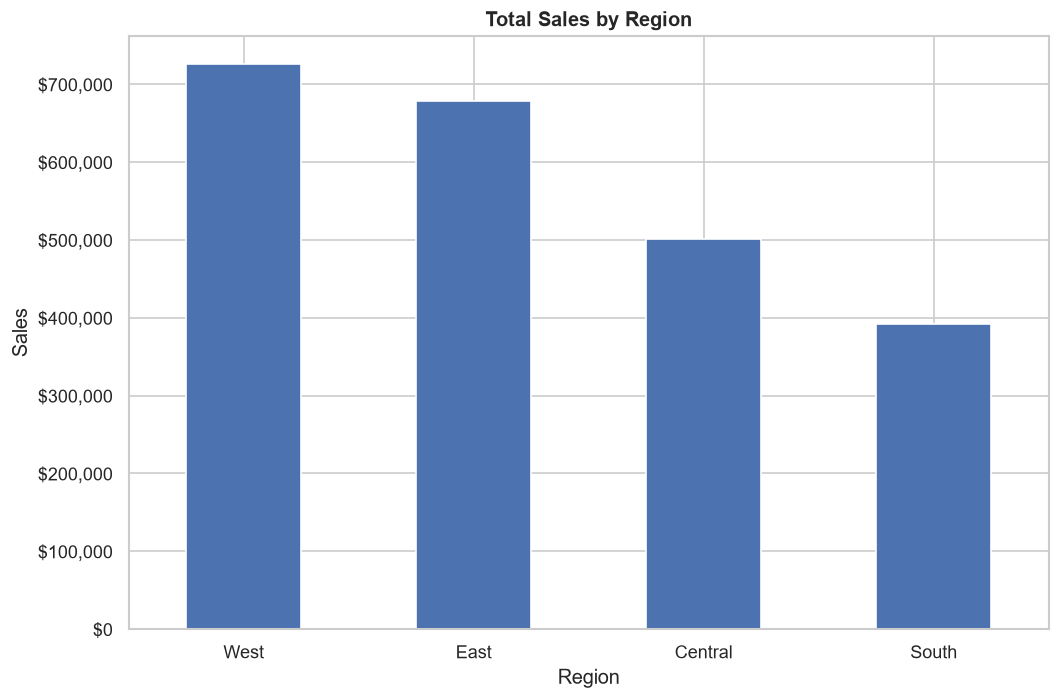

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\03_sales_by_region.png


In [52]:

if {"region", "sales"}.issubset(df.columns):
    region_sales = (
        df.groupby("region")["sales"]
        .sum()
        .sort_values(ascending=False)
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    region_sales.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title("Total Sales by Region")
    ax.set_xlabel("Region")
    ax.set_ylabel("Sales")
    ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
    )

    finish_chart(fig, "03_sales_by_region.png")
else:
    print("Required columns are missing.")


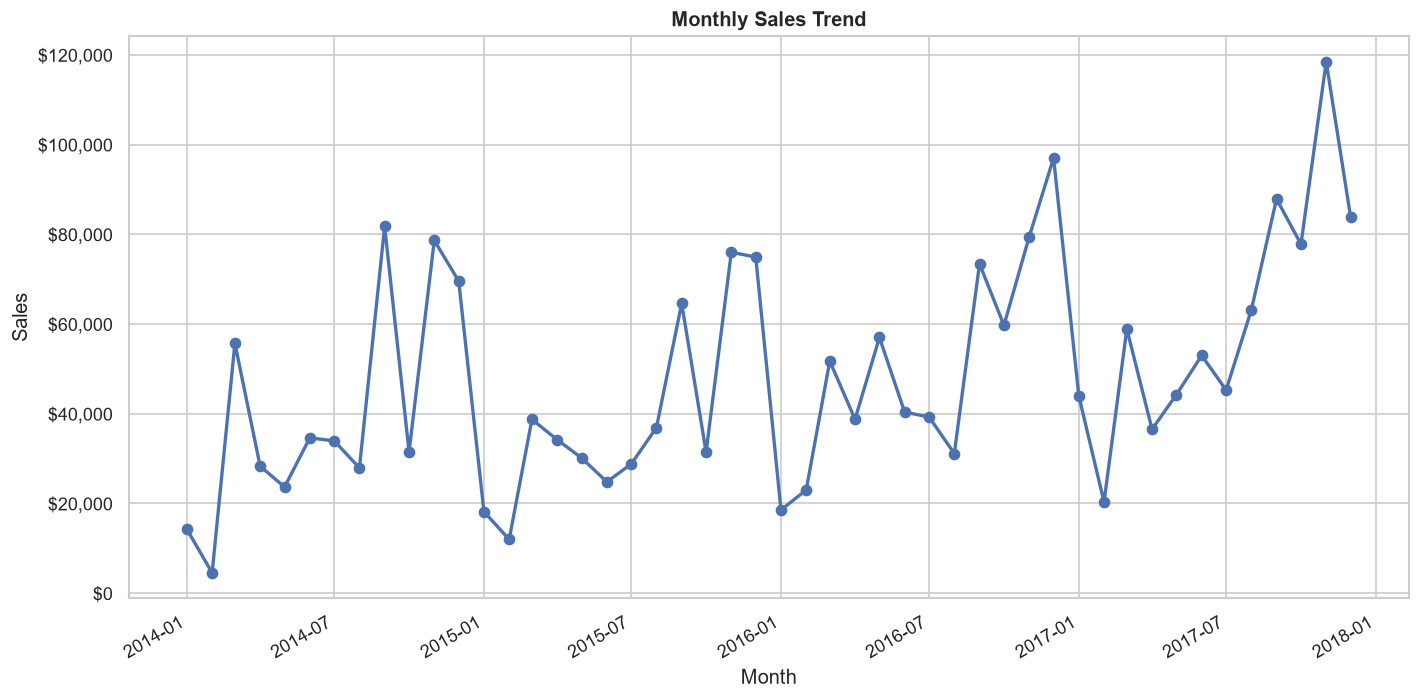

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\04_monthly_sales_trend.png


In [53]:

if {"order_date", "sales"}.issubset(df.columns):
    monthly_sales = (
        df.dropna(subset=["order_date"])
        .set_index("order_date")["sales"]
        .resample("MS")
        .sum()
    )

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        monthly_sales.index,
        monthly_sales.values,
        marker="o",
        linewidth=2
    )

    ax.set_title("Monthly Sales Trend")
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
    )

    fig.autofmt_xdate()

    finish_chart(fig, "04_monthly_sales_trend.png")
else:
    print("Check that order_date and sales exist.")


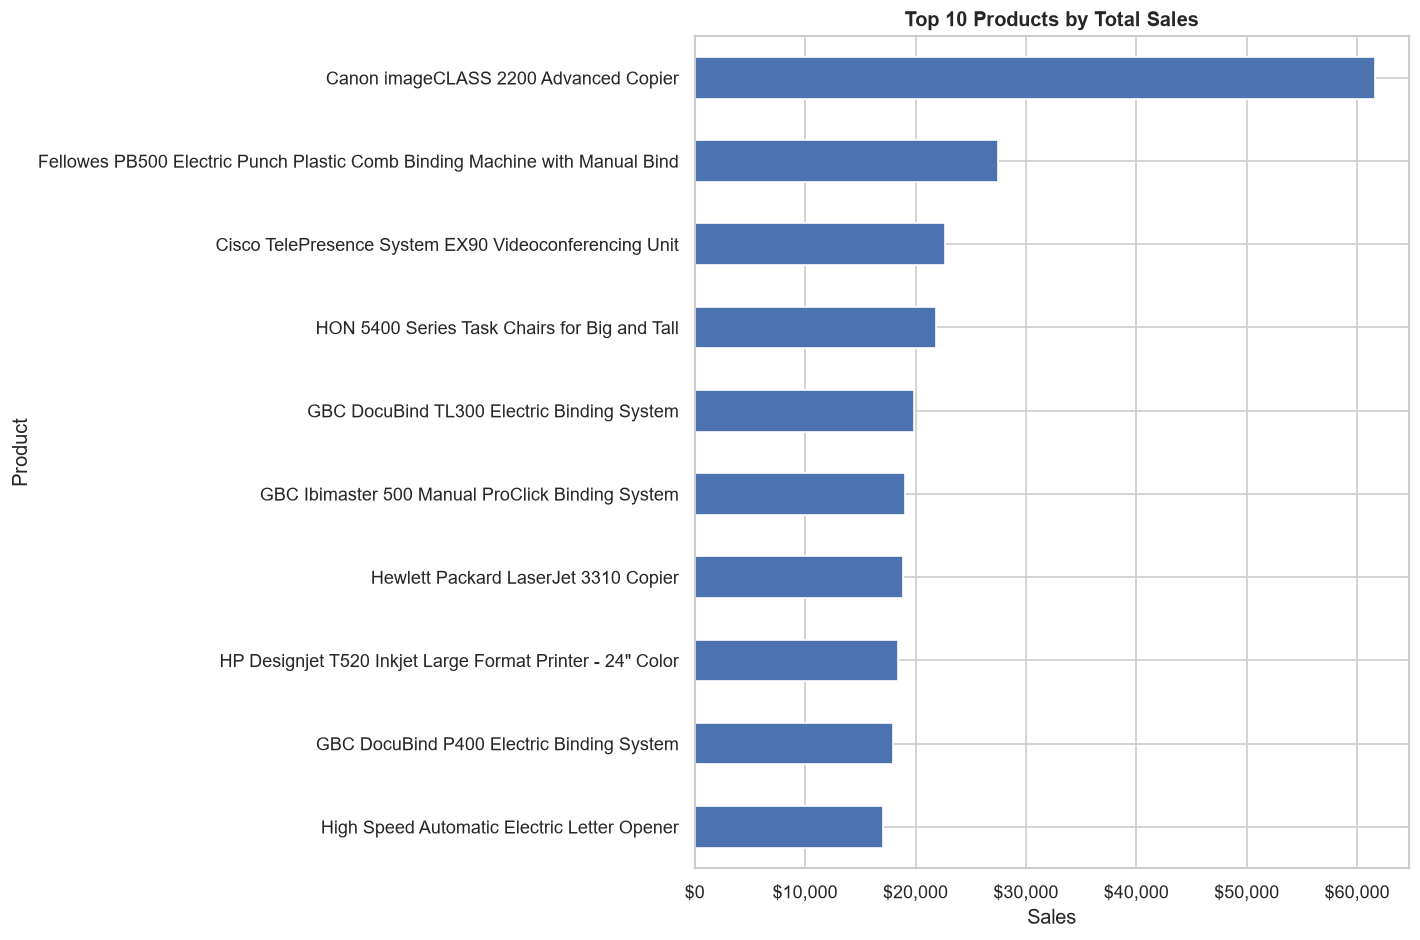

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\05_top_10_products_by_sales.png


In [54]:

if {"product_name", "sales"}.issubset(df.columns):
    top_products = (
        df.groupby("product_name")["sales"]
        .sum()
        .nlargest(10)
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(12, 8))

    top_products.plot(
        kind="barh",
        ax=ax
    )

    ax.set_title("Top 10 Products by Total Sales")
    ax.set_xlabel("Sales")
    ax.set_ylabel("Product")
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
    )

    finish_chart(fig, "05_top_10_products_by_sales.png")
else:
    print("Required columns are missing.")


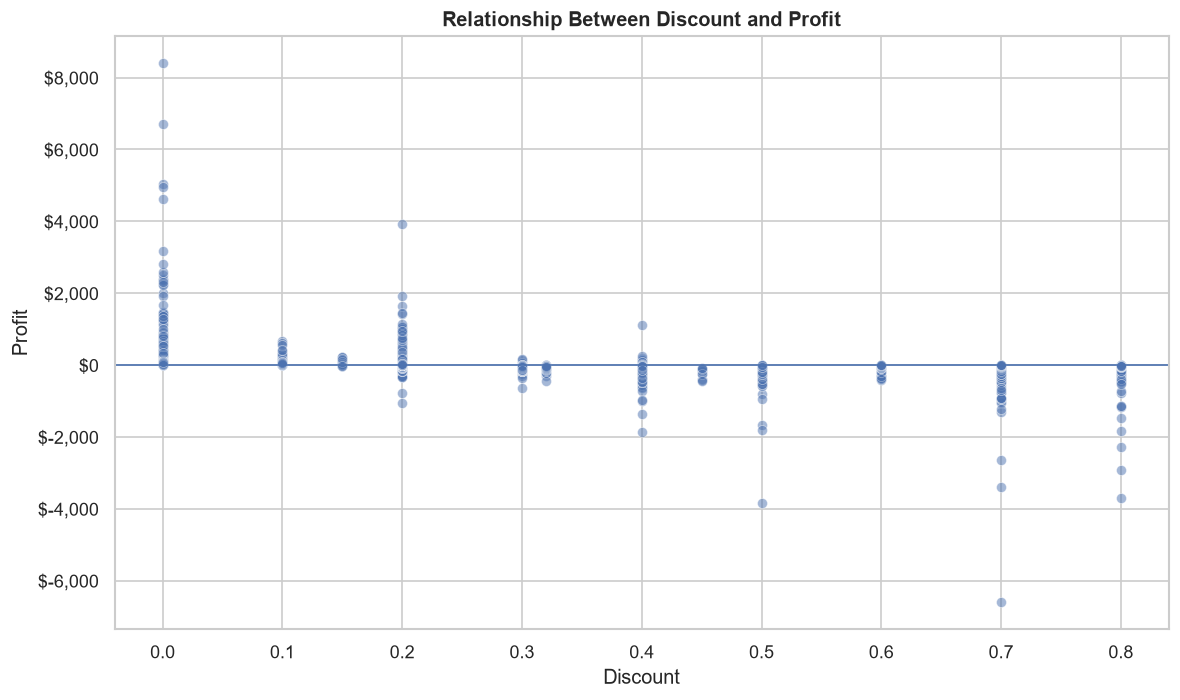

Saved: d:\AI\AI POWERED SALES ANALYTICS COPILOT\reports\figures\06_discount_vs_profit.png


In [55]:

if {"discount", "profit"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.scatterplot(
        data=df,
        x="discount",
        y="profit",
        alpha=0.5,
        ax=ax
    )

    ax.axhline(0, linewidth=1)
    ax.set_title("Relationship Between Discount and Profit")
    ax.set_xlabel("Discount")
    ax.set_ylabel("Profit")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"${y:,.0f}")
    )

    finish_chart(fig, "06_discount_vs_profit.png")
else:
    print("Required columns are missing.")


In [56]:

saved_charts = sorted(FIGURES_DIR.glob("*.png"))

print(f"Total saved charts: {len(saved_charts)}")

for chart in saved_charts:
    print(chart.name, "-", f"{chart.stat().st_size / 1024:.1f} KB")


Total saved charts: 6
01_sales_by_category.png - 52.1 KB
02_profit_by_subcategory.png - 99.0 KB
03_sales_by_region.png - 48.9 KB
04_monthly_sales_trend.png - 160.5 KB
05_top_10_products_by_sales.png - 138.7 KB
06_discount_vs_profit.png - 97.3 KB
